# 03 - Classification : prédiction du churn

In [1]:
import logging
import os
import warnings

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from xgboost import XGBClassifier

logging.getLogger("mlflow").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", module="mlflow")
sns.set_theme(style="whitegrid")

## Configuration et données

In [2]:
DATA_PATH = "data/processed/clean_eng.csv"
FIG_DIR = "reports/figures"
SEED = 42
MLFLOW_URI = "sqlite:///mlflow.db"
EXPERIMENT = "churn-prediction"
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

NUMERIC = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
ENGINEERED = ["charges_per_tenure", "is_new_customer", "is_month_to_month", "is_fiber", "is_electronic_check", "nb_services"]
ORDINAL = {
    "Contract": ["Month-to-month", "One year", "Two year"],
    "MultipleLines": ["No phone service", "No", "Yes"],
    "InternetService": ["No", "DSL", "Fiber optic"],
}
NOMINAL = [
    "gender", "Partner", "Dependents", "PhoneService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies", "PaperlessBilling", "PaymentMethod",
]

mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENT)

df = pd.read_csv(DATA_PATH)
y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["Churn", "customerID"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train:", X_train.shape, "test:", X_test.shape)
print("churn train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

train: (5634, 26) test: (1409, 26)
churn train / test: 0.265 / 0.265


### Preprocessing

In [3]:
def build_preprocessor(use_fe=True, use_cluster=False):
    num_cols = NUMERIC + (ENGINEERED if use_fe else [])
    nom_cols = NOMINAL + (["cluster"] if use_cluster else [])
    numeric = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
    ordinal = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OrdinalEncoder(categories=list(ORDINAL.values()), handle_unknown="use_encoded_value", unknown_value=-1),
    )
    nominal = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore", drop="if_binary"))
    return ColumnTransformer(
        [("num", numeric, num_cols), ("ord", ordinal, list(ORDINAL)), ("nom", nominal, nom_cols)],
        verbose_feature_names_out=False,
    )

### Pipeline et suivi MLflow

In [4]:
def make_model(clf, sampler=None):
    steps = [("prep", build_preprocessor())]
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("clf", clone(clf)))
    return Pipeline(steps)


def test_metrics(model, threshold=0.5):
    proba = model.predict_proba(X_test)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "test_accuracy": accuracy_score(y_test, pred),
        "test_precision": precision_score(y_test, pred),
        "test_recall": recall_score(y_test, pred),
        "test_f1": f1_score(y_test, pred),
        "test_roc_auc": roc_auc_score(y_test, proba),
    }


def run_experiment(name, clf, sampler=None, threshold=0.5, tags=None):
    model = make_model(clf, sampler)
    cv = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    metrics = {f"cv_{s}": cv[f"test_{s}"].mean() for s in SCORING}
    metrics["cv_roc_auc_std"] = cv["test_roc_auc"].std()
    model.fit(X_train, y_train)
    metrics.update(test_metrics(model, threshold))

    with mlflow.start_run(run_name=name):
        mlflow.set_tags({"model": type(clf).__name__, **(tags or {})})
        mlflow.log_params(
            {
                "use_feature_engineering": True,
                "use_cluster": False,
                "sampler": type(sampler).__name__ if sampler is not None else "none",
                "scaler": "StandardScaler",
                "encoding": "OneHot(nominal) + Ordinal(Contract, MultipleLines, InternetService)",
                "imputation": "median(num) / most_frequent(cat)",
                "split": "80/20 stratified, seed 42",
                "threshold": threshold,
            }
        )
        mlflow.log_params({f"clf__{k}": v for k, v in clf.get_params().items()})
        mlflow.log_metrics(metrics)
        pred = (model.predict_proba(X_test)[:, 1] >= threshold).astype(int)
        cm = ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Reste", "Churn"], cmap="Blues")
        mlflow.log_figure(cm.figure_, "confusion_matrix.png")
        roc = RocCurveDisplay.from_estimator(model, X_test, y_test)
        mlflow.log_figure(roc.figure_, "roc_curve.png")
        plt.close("all")
        mlflow.sklearn.log_model(model, name="model", input_example=X_test.head(3), serialization_format="cloudpickle")
    return model, metrics

### Modèles testés

In [5]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier


def models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
        "Decision Tree": DecisionTreeClassifier(random_state=SEED),
        "Random Forest": RandomForestClassifier(random_state=SEED),
        "SVM": CalibratedClassifierCV(SVC(random_state=SEED), ensemble=False),
        "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
        "XGBoost": XGBClassifier(random_state=SEED),
    }


def table(results):
    return pd.DataFrame(results).T[["cv_precision", "cv_recall", "cv_f1", "cv_roc_auc", "test_f1", "test_roc_auc"]].round(4)

## 1. Modèles de base (sans rééquilibrage)

In [6]:
baseline = {}
for name, clf in models().items():
    _, baseline[name] = run_experiment(name, clf, tags={"stage": "baseline"})
table(baseline).sort_values("cv_roc_auc", ascending=False)

,cv_precision,cv_recall,cv_f1,cv_roc_auc,test_f1,test_roc_auc
Logistic Regression,0.6724,0.5278,0.5908,0.8487,0.5889,0.8457
Gradient Boosting,0.6660,0.5204,0.5840,0.8461,0.5831,0.8423
Random Forest,0.6409,0.5043,0.5642,0.8259,0.5478,0.8205
XGBoost,0.6124,0.5030,0.5523,0.8242,0.5528,0.8201
SVM,0.6843,0.4482,0.5412,0.7966,0.5388,0.7897
Decision Tree,0.4982,0.5037,0.5008,0.6606,0.5020,0.6608


## 2. Gestion du déséquilibre

In [7]:
strategies = {
    "aucune": (LogisticRegression(max_iter=1000, random_state=SEED), None),
    "class_weight": (LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED), None),
    "Random Oversampling": (LogisticRegression(max_iter=1000, random_state=SEED), RandomOverSampler(random_state=SEED)),
    "SMOTE": (LogisticRegression(max_iter=1000, random_state=SEED), SMOTE(random_state=SEED)),
}
imbalance = {}
for name, (clf, sampler) in strategies.items():
    _, imbalance[name] = run_experiment(f"LogReg - {name}", clf, sampler=sampler, tags={"stage": "imbalance"})
table(imbalance)

,cv_precision,cv_recall,cv_f1,cv_roc_auc,test_f1,test_roc_auc
aucune,0.6724,0.5278,0.5908,0.8487,0.5889,0.8457
class_weight,0.5251,0.7973,0.6330,0.8485,0.6157,0.8455
Random Oversampling,0.5235,0.7987,0.6323,0.8482,0.6173,0.8463
SMOTE,0.5286,0.7920,0.6338,0.8470,0.6165,0.8448


## 3. Tous les modèles avec SMOTE

In [8]:
smote_results, fitted = {}, {}
for name, clf in models().items():
    fitted[name], smote_results[name] = run_experiment(f"{name} + SMOTE", clf, sampler=SMOTE(random_state=SEED), tags={"stage": "smote"})
smote_table = table(smote_results).sort_values("cv_roc_auc", ascending=False)
smote_table

,cv_precision,cv_recall,cv_f1,cv_roc_auc,test_f1,test_roc_auc
Logistic Regression,0.5286,0.7920,0.6338,0.8470,0.6165,0.8448
Gradient Boosting,0.5999,0.6575,0.6272,0.8457,0.6055,0.8416
SVM,0.5469,0.7291,0.6248,0.8264,0.6223,0.8215
Random Forest,0.5960,0.5712,0.5829,0.8212,0.5653,0.8216
XGBoost,0.5958,0.5505,0.5718,0.8202,0.5971,0.8217
Decision Tree,0.4889,0.5278,0.5076,0.6651,0.5137,0.6684


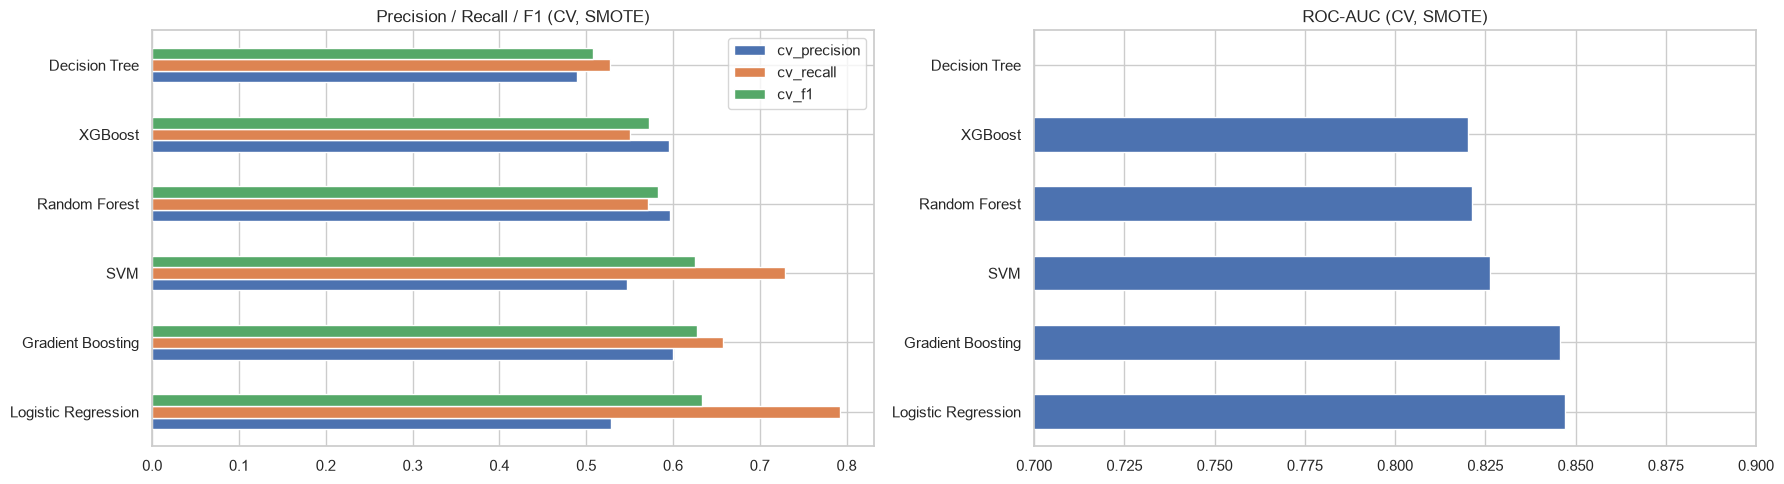

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
smote_table[["cv_precision", "cv_recall", "cv_f1"]].plot.barh(ax=axes[0])
axes[0].set_title("Precision / Recall / F1 (CV, SMOTE)")
smote_table[["cv_roc_auc"]].plot.barh(ax=axes[1], legend=False, xlim=(0.7, 0.9))
axes[1].set_title("ROC-AUC (CV, SMOTE)")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/20_model_comparison.png", dpi=110, bbox_inches="tight")
plt.show()

## 4. Courbes ROC (test)

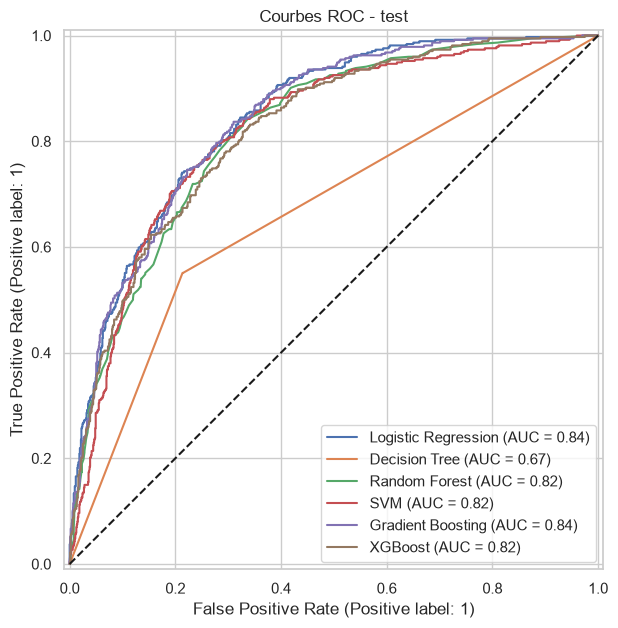

In [10]:
fig, ax = plt.subplots(figsize=(8, 7))
for name, model in fitted.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--")
ax.set_title("Courbes ROC - test")
fig.savefig(f"{FIG_DIR}/21_roc_curves.png", dpi=110, bbox_inches="tight")
plt.show()